# Time-series + snapshot transformer: demo of the requested design

This notebook walks through the whole pipeline with the **requested architecture**. The prediction head gets three CLS tokens:

```
[ CLS regular time-series values | CLS missing & special values | CLS snapshot variables ]  ->  regression head
```

| Section | Content |
|---|---|
| 1 | Data as delivered: time-series frame, missing and special indicator frames, PLE snapshot frame, target |
| 2 | From DataFrames to aligned arrays: the data structures the model consumes |
| 3 | Special-value treatment: one state code per cell, statistics on regular cells only, re-imputation |
| 4 | Tokenizer: sliding patches per variable |
| 5 | Model: factorized attention (variables, then time) with a 2-D CLS grid; three branches; head |
| 6 | Training with **MSE**: per-epoch metrics, logs, checkpoints, early stopping, best model by validation RMSE |
| 7 | Training with **Tweedie** loss and tuning the power `p` |
| 8 | Reloading the best checkpoint, then predicting and evaluating |
| 9 | Checklist for running on your data |

The data here is **synthetic** but has the same layout as yours: 11 time steps, missing values imputed as 0, special sentinel values, PLE snapshot vectors, and a positive right-skewed target. Replace section 1 with your own loading code; nothing downstream changes.

### Architecture

```
x      (B, T=11, V) ─► sliding patches per variable (B, V, Np, P) ─► value patch embedding ─────┐
state  (B, T, V)    ─► same patches ─► ONE embedding per state (shared by all variables) ──┐   │
                                                                                        │   ▼
          ┌──────────────────── 2-D token grid with CLS row / column ────────────────┐  │  grid encoder A
          │ [CLS global] [CLS t1] ... [CLS tNp]   ← each sums up one patch position    │  │  L × (attention across
          │ [CLS var1 ]  p(1,1)  ...  p(1,Np)                                          │  │       variables ─►
          │   ...                                                                      │  │       attention across
          │ [CLS varV ]  p(V,1)  ...  p(V,Np)                                          │  │       time ─► FFN)
          └────────────────────────────────────────────────────────────────────────────┘  ▼
                                                              grid encoder B (same structure, state tokens)
snapshot PLE (B, S, bins) ─► per-variable linear embedding ─► [CLS] + S tokens ─► transformer

head( concat[ CLS_regular , CLS_missing/special , CLS_snapshot ] ) ─► ŷ
```

In [1]:
import sys, os, math, time, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from tsfusion import (ModelConfig, TrainConfig, RawData, Preprocessor, Trainer, TSFusionTransformer,
                      long_df_to_array, group_columns_by_prefix, build_state, default_target_mode,
                      load_checkpoint, predict_with, regression_metrics, count_parameters,
                      tweedie_deviance)
from tsfusion.model import SlidingPatcher
from tsfusion.synthetic import make_synthetic_dataset

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if HAS_GPU else "cpu"   # ONE GPU (pick another with "cuda:1" or CUDA_VISIBLE_DEVICES)
print("torch", torch.__version__, "| CUDA:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")

RUNS = REPO / "runs" / "demo_late_fusion"
# CPU-friendly settings so the notebook also runs without a GPU. On a GPU use the larger values.
SMALL = not HAS_GPU
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

torch 2.15.0+cu132 | CUDA: False | CPU only


## 1. Data as delivered

Five objects come in, all keyed by `record_id`:

| object | layout | notes |
|---|---|---|
| `ts_df` | long: index `(record_id, time_step)`, one column per variable | missing cells **imputed as 0**; special cells hold a sentinel (here -999/-998/-997) |
| `missing_df` | same layout, 0/1 | 1 = the value was missing |
| `special_df` | same layout, integer code | 0 = not special, `k` = special value `k`; each code means the same thing for every variable |
| `snapshot_ple_df` | one row per record, columns `<feature>_bin<j>` | piecewise linear encoding of each snapshot variable (bins fitted on train) |
| `y` | one value per record | positive, right-skewed, a few extreme values |

> If your special-value frame is only a 0/1 flag and the value column holds the sentinel, `tsfusion.encode_special_values(x_raw, {-999: 1, -998: 2, ...}, special_mask)` turns it into codes.

In [2]:
data = make_synthetic_dataset(n_records=6000, n_vars=8, n_special_codes=3, seed=0)
ts_df, missing_df, special_df = data["ts_df"], data["missing_df"], data["special_df"]
snapshot_ple_df, snapshot_raw_df, y = data["snapshot_ple_df"], data["snapshot_raw_df"], data["y"]
train_ids, val_ids = data["train_ids"], data["val_ids"]          # your existing split
var_names, time_steps = data["var_names"], data["time_steps"]
N_SPECIAL = data["n_special_codes"]

print(f"ts_df        {ts_df.shape}  = ({ts_df.index.get_level_values(0).nunique()} records x "
      f"{ts_df.index.get_level_values(1).nunique()} steps, {ts_df.shape[1]} variables)")
print(f"missing_df   {missing_df.shape}   special_df {special_df.shape}")
print(f"snapshot_ple {snapshot_ple_df.shape}   y {y.shape}   train {len(train_ids)}  val {len(val_ids)}")
print("special sentinels -> code:", data["special_sentinels"])
ts_df.head(11).round(1)

ts_df        (66000, 8)  = (6000 records x 11 steps, 8 variables)
missing_df   (66000, 8)   special_df (66000, 8)
snapshot_ple (6000, 42)   y (6000,)   train 4800  val 1200
special sentinels -> code: {-999.0: 3, -998.0: 2, -997.0: 1}


var_00  var_01  var_02  var_03  var_04  var_05  var_06  var_07
record_id time_step                                                                
100000    1          -189.7   368.7  -997.0  -340.7   118.2   747.6     0.0   425.6
          2          -475.5   204.4   -87.4  -159.9   284.2   657.7     0.0     0.0
          3          -554.4   343.1    68.1  -125.1   249.8   562.6     0.0   420.2
          4          -544.5   259.6   109.6  -159.9   296.9   668.2     0.0   447.1
          5             0.0   184.6   462.7  -209.6     0.0   559.3     0.0   445.8
          6          -109.4   190.1   183.5  -296.2   241.9   761.3     0.0   449.2
          7            21.2   191.9   202.5  -220.7   190.2   823.4     0.0   447.6
          8           -21.6   319.4   219.4  -216.9   190.1   815.0     0.0   441.0
          9           150.0   273.1   311.7  -342.1   201.9   718.9     0.0   446.6
          10          212.9   347.3   558.3  -233.5   289.3   722.2  -455.9   451.1
          11          317.2   149.9   566.6   -91.9   182.2     0.0  -496.5   423.5

One record with both missing and special cells. The three frames are aligned cell by cell:

In [3]:
rid = next(r for r in train_ids
           if missing_df.loc[r].values.sum() >= 3 and special_df.loc[r].values.sum() >= 2)
pd.concat({"value": ts_df.loc[rid].round(1), "missing": missing_df.loc[rid],
           "special": special_df.loc[rid]}, axis=1).iloc[:, [0, 1, 2, 8, 9, 10, 16, 17, 18]]

value               missing               special              
          var_00 var_01 var_02  var_00 var_01 var_02  var_00 var_01 var_02
time_step                                                                 
1            0.0  243.2  201.7       1      0      0       0      0      0
2         -175.8  164.3  280.3       0      0      0       0      0      0
3         -285.8  326.8  462.1       0      0      0       0      0      0
4         -226.2  155.6  487.4       0      0      0       0      0      0
5         -384.6  166.0  519.5       0      0      0       0      0      0
6          -84.1  223.1  601.4       0      0      0       0      0      0
7           67.6  389.5  433.3       0      0      0       0      0      0
8          211.7 -998.0  493.4       0      0      0       0      2      0
9           26.9  427.7  351.1       0      0      0       0      0      0
10          96.5  408.4  489.5       0      0      0       0      0      0
11         -14.8  505.3  427.2       0      0      0       0      0      0

**Snapshot variables (PLE).** Each raw variable becomes a vector with one entry per quantile bin: 1 for bins entirely below the value, the fractional position inside the bin containing it, and 0 above. Different variables can have different numbers of bins.

In [4]:
ple_groups = group_columns_by_prefix(snapshot_ple_df.columns)       # [(feature, [cols...]), ...]
ple_cols = [c for _, cols in ple_groups for c in cols]
group_sizes = [len(cols) for _, cols in ple_groups]
print("snapshot features and #bins:", {name: len(cols) for name, cols in ple_groups})
r = train_ids[0]
print(f"\nrecord {r}: raw income = {snapshot_raw_df.loc[r, 'income']:.0f}")
snapshot_ple_df.loc[[r], [c for c in ple_cols if c.startswith("income")]].round(3)

snapshot features and #bins: {'age': 8, 'income': 10, 'tenure_m': 6, 'score': 10, 'utilization': 8}

record 100000: raw income = 15671


,income_bin0,income_bin1,income_bin2,income_bin3,income_bin4,income_bin5,income_bin6,income_bin7,income_bin8,income_bin9
record_id,,,,,,,,,,
100000,0.742,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


count      6000.0
mean       2719.8
std        5317.9
min           4.8
50%        1173.6
90%        6154.6
99%       22640.7
99.9%     58097.8
max      120448.1
skewness = 7.9   max/median = 103x   min = 4.85 (> 0)


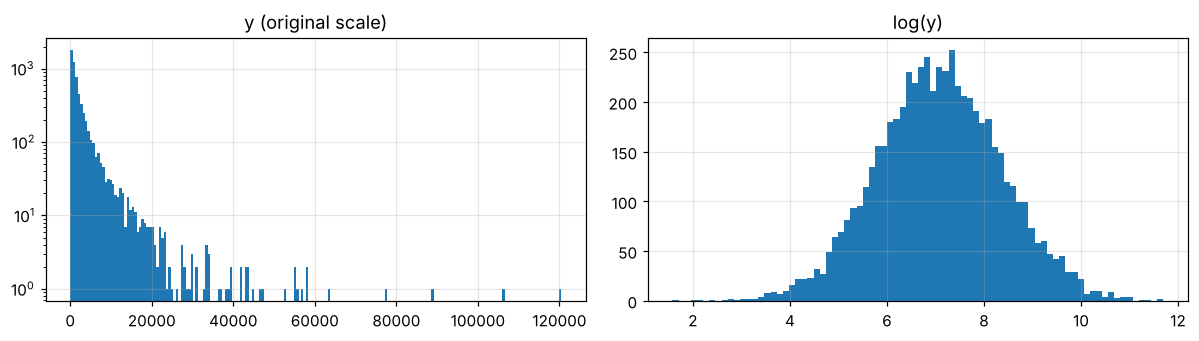

In [5]:
print(y.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
print(f"skewness = {y.skew():.1f}   max/median = {y.max() / y.median():.0f}x   min = {y.min():.2f} (> 0)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(y, bins=200); ax[0].set_title("y (original scale)"); ax[0].set_yscale("log")
ax[1].hist(np.log(y), bins=80); ax[1].set_title("log(y)")
plt.tight_layout(); plt.show()

## 2. From DataFrames to arrays

The model consumes these aligned arrays. All of them must use the **same record order**, so we pass `record_ids` explicitly:

| array | shape | dtype |
|---|---|---|
| `x` | `(N, T, V)` | float32 |
| `missing` | `(N, T, V)` | 0/1 |
| `special` | `(N, T, V)` | int, 0..K |
| `snapshot` | `(N, Σ bins)`: the PLE columns of all snapshot variables side by side | float32 |
| `y` | `(N,)` | float |

`long_df_to_array` reindexes every frame to the full `record_id × time_step` grid. A record with fewer than 11 rows gets the fill value: NaN for values (treated as missing), 1 for the missing flag and 0 for the special code. If your frame is wide (`bal_t1 … bal_t11`), use `tsfusion.wide_df_to_array`.

In [6]:
def to_raw(ids) -> RawData:
    kw = dict(value_cols=var_names, record_ids=ids, time_steps=time_steps)
    x, _ = long_df_to_array(ts_df, **kw)
    miss, _ = long_df_to_array(missing_df, fill_value=1, **kw)
    spec, _ = long_df_to_array(special_df, fill_value=0, **kw)
    return RawData(x=x, missing=miss, special=spec.astype(np.int64),
                   snapshot=snapshot_ple_df.loc[ids, ple_cols].to_numpy(),
                   y=y.loc[ids].to_numpy())

train_raw, val_raw = to_raw(train_ids), to_raw(val_ids)
pd.DataFrame({k: [getattr(train_raw, k).shape, getattr(val_raw, k).shape, getattr(train_raw, k).dtype]
              for k in ["x", "missing", "special", "snapshot", "y"]},
             index=["train", "validation", "dtype"])

,x,missing,special,snapshot,y
train,"(4800, 11, 8)","(4800, 11, 8)","(4800, 11, 8)","(4800, 42)","(4800,)"
validation,"(1200, 11, 8)","(1200, 11, 8)","(1200, 11, 8)","(1200, 42)","(1200,)"
dtype,float32,float32,int64,float32,float64


## 3. Special-value treatment

**3.1 One state per cell.** Missing and special flags merge into one integer `state`, and the model learns **one embedding per state**, shared by every variable and time step. This matches the fact that each code means the same thing for every feature.

| state | meaning |
|---|---|
| 0 | regular (observed) value |
| 1 | missing |
| 1 + k | special value k (k = 1..K) |

A cell flagged as both missing and special counts as special (the more specific information), and a warning is raised. A NaN in `x` is treated as missing.

share of cells by state (%):
regular             84.75
missing             12.41
special 2 (-998)     1.13
special 1 (-997)     0.86
special 3 (-999)     0.85


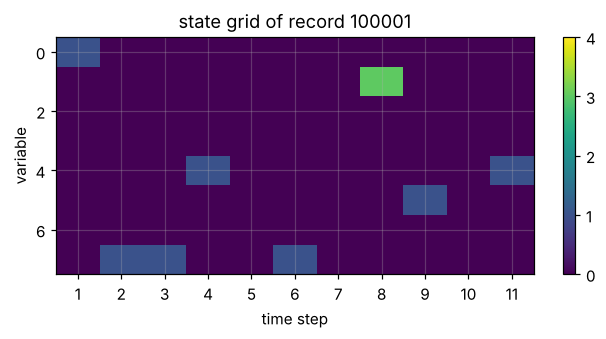

In [7]:
state_tr = build_state(train_raw.missing, train_raw.special)
names = {0: "regular", 1: "missing", **{1 + k: f"special {k} ({s:.0f})"
         for s, k in data["special_sentinels"].items()}}
share = pd.Series(state_tr.ravel()).map(names).value_counts(normalize=True).mul(100).round(2)
print("share of cells by state (%):"); print(share.to_string())

rec = list(train_ids).index(rid)
fig, ax = plt.subplots(figsize=(7, 2.8))
im = ax.imshow(state_tr[rec].T, cmap="viridis", vmin=0, vmax=1 + N_SPECIAL, aspect="auto")
ax.set_xlabel("time step"); ax.set_ylabel("variable"); ax.set_xticks(range(11), time_steps)
ax.set_title(f"state grid of record {rid}"); plt.colorbar(im, ticks=range(2 + N_SPECIAL)); plt.show()

**3.2 Scaling uses regular cells only.** Sentinels such as -999 and the imputed zeros would wreck the per-variable mean and std, so they are excluded. Here is the difference:

In [8]:
xs = train_raw.x.reshape(-1, len(var_names)); reg = (state_tr == 0).reshape(-1, len(var_names))
pd.DataFrame({"naive mean": xs.mean(0), "regular-only mean": [xs[reg[:, v], v].mean() for v in range(len(var_names))],
              "naive std": xs.std(0), "regular-only std": [xs[reg[:, v], v].std() for v in range(len(var_names))]},
             index=var_names).astype(float).round(1)

,naive mean,regular-only mean,naive std,regular-only std
var_00,2.0,34.8,508.5,519.7
var_01,344.0,439.9,355.1,246.2
var_02,513.4,639.5,566.9,496.1
var_03,208.0,278.8,553.5,549.1
var_04,334.6,426.0,570.9,549.1
var_05,711.6,873.6,465.0,239.5
var_06,73.6,121.3,616.0,638.6
var_07,340.6,436.2,272.7,39.8


**3.3 Preprocessor.** It is fitted on the **training split only**, then applied to every split. It:

1. standardises each variable with the regular-only statistics and clips to ±10,
2. sets every non-regular cell to **exactly 0**. After standardisation the upstream "impute 0" is no longer 0, so we re-impute. The model also zeroes these cells itself, so stray sentinels can never leak in,
3. packs the PLE columns into `(N, S, max_bins)`, zero-padding the shorter groups,
4. transforms the target according to the loss:
   * **MSE**: `standard`, i.e. `(y − mean) / std`. The loss is then on the original scale, which is what validation RMSE measures.
   * **Tweedie**: `mean_scale`, i.e. `y / mean(y)`. It stays positive, and the log-link output starts at 0.

In [9]:
prep_mse = Preprocessor(n_special_codes=N_SPECIAL, snapshot_group_sizes=group_sizes,
                        snapshot_kind="ple", target_mode=default_target_mode("mse")).fit(train_raw)
train_mse, val_mse = prep_mse.transform(train_raw), prep_mse.transform(val_raw)

print("x       ", tuple(train_mse.x.shape), train_mse.x.dtype)
print("state   ", tuple(train_mse.state.shape), train_mse.state.dtype, "values", torch.unique(train_mse.state).tolist())
print("snapshot", tuple(train_mse.snapshot.shape), "(N, S snapshot vars, max bins)")
print("y       ", tuple(train_mse.y.shape), "transformed; y_raw kept for metrics")
nonreg = train_mse.state != 0
print("all non-regular cells are 0:", bool((train_mse.x[nonreg] == 0).all()))
pd.DataFrame(train_mse.x[rec].numpy(), index=time_steps, columns=var_names).round(2).T

x        (4800, 11, 8) torch.float32
state    (4800, 11, 8) torch.uint8 values [0, 1, 2, 3, 4]
snapshot (4800, 5, 10) (N, S snapshot vars, max bins)
y        (4800,) transformed; y_raw kept for metrics
all non-regular cells are 0: True


,1,2,3,4,5,6,7,8,9,10,11
var_00,0.00,-0.41,-0.62,-0.50,-0.81,-0.23,0.06,0.34,-0.02,0.12,-0.10
var_01,-0.80,-1.12,-0.46,-1.15,-1.11,-0.88,-0.20,0.00,-0.05,-0.13,0.27
var_02,-0.88,-0.72,-0.36,-0.31,-0.24,-0.08,-0.42,-0.29,-0.58,-0.30,-0.43
var_03,-0.42,-0.29,-0.43,-0.67,-0.91,-0.80,-0.78,-0.66,-0.59,-0.91,-1.02
var_04,-0.62,-0.60,-0.55,0.00,-0.05,-0.18,-0.49,-0.20,-0.50,0.49,0.00
var_05,-0.06,-0.35,-0.13,-0.28,-0.19,-0.04,0.04,-0.15,0.00,-0.01,-0.02
var_06,-0.58,-0.79,-0.58,-0.55,-0.31,0.09,-0.26,-0.36,-0.65,-0.40,-0.55
var_07,-0.61,0.00,0.00,0.10,0.40,0.00,0.16,0.23,-0.40,-0.49,-0.13


## 4. Tokenizer: sliding patches per variable

Each variable's 11-step series is cut into overlapping windows of `patch_len` steps, moving `patch_stride` steps each time. Each window becomes one token, so the number of patches is `Np = (T + pad − P) / S + 1`. When `(T − P)` is not a multiple of the stride, the series is right-padded by repeating its last step, so the **most recent step is always covered**. The same windows are applied to the state tensor so values and states stay aligned.

With T = 11 there is little room: `P=3, S=1` gives 9 tokens per variable, and `P=4, S=2` gives 5.

In [10]:
P, S = 3, 1
patcher = SlidingPatcher(n_steps=11, patch_len=P, stride=S)
xp = patcher(train_mse.x[rec:rec + 1])                    # (1, V, Np, P)
sp = patcher(train_mse.state[rec:rec + 1].long())
print(f"patch_len={P} stride={S} -> {patcher.n_patches} patches per variable, x patches shape {tuple(xp.shape)}")
v = 0
pd.DataFrame({"time steps": [f"t{1 + i * S}..t{i * S + P}" for i in range(patcher.n_patches)],
              "values": [[round(float(a), 2) for a in p] for p in xp[0, v]],
              "states": [s.tolist() for s in sp[0, v]]}).set_index("time steps")

patch_len=3 stride=1 -> 9 patches per variable, x patches shape (1, 8, 9, 3)


,values,states
time steps,,
t1..t3,"[0.0, -0.41, -0.62]","[1, 0, 0]"
t2..t4,"[-0.41, -0.62, -0.5]","[0, 0, 0]"
t3..t5,"[-0.62, -0.5, -0.81]","[0, 0, 0]"
t4..t6,"[-0.5, -0.81, -0.23]","[0, 0, 0]"
t5..t7,"[-0.81, -0.23, 0.06]","[0, 0, 0]"
t6..t8,"[-0.23, 0.06, 0.34]","[0, 0, 0]"
t7..t9,"[0.06, 0.34, -0.02]","[0, 0, 0]"
t8..t10,"[0.34, -0.02, 0.12]","[0, 0, 0]"
t9..t11,"[-0.02, 0.12, -0.1]","[0, 0, 0]"


## 5. Model

**Branch A: regular values.** Each patch of `P` standardised values goes through a linear layer to `d_model`. With `patch_include_mask=True`, the `P` "is regular" bits are appended first, so the network can tell an imputed 0 from a real 0. Patches without any regular value are **hidden from attention** (`mask_empty_patches`), so this CLS reflects regular values only.

**Factorized attention with a 2-D CLS grid** (BERT's [CLS], extended to two axes):
* row 0 holds a `[CLS time_n]` per patch position, column 0 holds a `[CLS var_v]` per variable, and `[CLS global]` sits at (0, 0);
* **attention across variables** runs within each column, so `[CLS time_n]` collects all variables at position n;
* **attention across time** runs within each row, so `[CLS global]` collects every `[CLS time_n]` and `[CLS var_v]` collects variable v's history;
* after **one** block the global CLS has seen every patch. Stacking `L` blocks lets the variable and time patterns refine each other.

**Branch B: missing and special values.** The same patch windows are applied to the state codes. There is **one embedding per state** (`nn.Embedding(2 + K, state_emb_dim)`), shared by all variables. Each patch's `P` state embeddings are concatenated and projected, and the result goes through the same kind of grid encoder. Patches with **no** missing or special cell are hidden, so a record with no missing or special values gets one learned "nothing unusual" embedding.

**Branch C: snapshot.** Each snapshot variable's PLE vector gets its **own** linear layer (FT-Transformer-style feature tokenizer). The tokens get a `[CLS]` and go through a small transformer. A raw numeric variable would simply be a group of size 1.

**Head.** LayerNorm, then an MLP on `concat[CLS_A, CLS_B, CLS_C]`, giving one output on the *link* scale: identity for MSE, `log μ` for Tweedie.

In [11]:
model_cfg = ModelConfig(
    n_vars=len(var_names), n_steps=11, n_special_codes=N_SPECIAL, snapshot_group_sizes=group_sizes,
    patch_len=3, patch_stride=1, patch_include_mask=True, state_emb_dim=16,
    d_model=32 if SMALL else 64, n_heads=4, ff_mult=2 if SMALL else 4, dropout=0.1,
    n_ts_layers=2, n_special_layers=1, n_snapshot_layers=1,
    missing_fusion="late",              # <- the requested design: 3 CLS tokens
    head_hidden=128, head_dropout=0.1)
model = TSFusionTransformer(model_cfg)
print(f"total trainable parameters: {count_parameters(model):,}")
for name, child in model.named_children():
    print(f"  {name:18s} {count_parameters(child):>9,}  {type(child).__name__}")

total trainable parameters: 64,913
  patcher                    0  SlidingPatcher
  value_embed              224  ValuePatchEmbedding
  ts_encoder            26,368  GridEncoder
  state_embed            1,648  StatePatchEmbedding
  special_encoder       13,536  GridEncoder
  snapshot_encoder      10,400  SnapshotEncoder
  head                  12,737  RegressionHead


In [12]:
model.eval()
b = slice(0, 8)
with torch.no_grad():
    emb = model.embed(train_mse.x[b], train_mse.state[b], train_mse.snapshot[b])
    out = model(train_mse.x[b], train_mse.state[b], train_mse.snapshot[b])
for k, v in emb.items():
    print(f"{k:13s} {tuple(v.shape)}")
print(f"head input    {(8, sum(v.shape[1] for v in emb.values()))}  -> output {tuple(out.shape)}")
print(f"token grid per branch: (V+1) x (Np+1) = {len(var_names) + 1} x {model.n_patches + 1}")

cls_ts        (8, 32)
cls_special   (8, 32)
cls_snapshot  (8, 32)
head input    (8, 96)  -> output (8,)
token grid per branch: (V+1) x (Np+1) = 9 x 10


## 6. Training with MSE

Every epoch, `Trainer.fit`:
1. trains on the training data in shuffled mini-batches on **one GPU**: AdamW, mixed precision (bf16 when available), gradient clipping, and a linear warm-up followed by ReduceLROnPlateau on validation RMSE;
2. computes **RMSE, MAE, R², NMAD** on the **original target scale** in eval mode, for the training data (optionally a fixed subset, `train_eval_max_samples`) and the validation data, plus each split's loss;
3. appends one row to `metrics.csv` and one line to `train.log`, and saves `epoch_XXX.pt` (model, optimizer, scheduler, configs and the fitted preprocessor);
4. saves `best_model.pt` when validation RMSE reaches a new low (**model selection**);
5. **stops early** after `early_stopping_patience` epochs without a validation RMSE improvement larger than `early_stopping_min_delta`, then restores the best weights.

NMAD = 1.4826 · median(|e − median(e)|) with e = ŷ − y. It is a robust measure of error spread that the few extreme targets cannot dominate (RMSE can).

In [13]:
steps_per_epoch = math.ceil(len(train_raw) / 256)
train_cfg = TrainConfig(
    loss="mse", batch_size=256, max_epochs=40 if SMALL else 150, lr=1e-3, weight_decay=1e-4,
    warmup_steps=2 * steps_per_epoch, scheduler="plateau", plateau_patience=3, grad_clip=1.0,
    early_stopping_patience=8, device=DEVICE, use_amp=True,
    output_dir=str(RUNS / "mse"), train_eval_max_samples=2000, seed=42)

trainer = Trainer(model_cfg, train_cfg, prep_mse)
hist_mse = trainer.fit(train_mse, val_mse)

03:53:14 | device=cpu amp=off params=64,913 train=4,800 val=1,200 loss=mse fusion=late


03:53:23 | epoch   1 | lr 5.00e-04 | train loss 0.9931 rmse 5786.9706 mae 2461.8001 r2 0.0411 nmad 1129.6039 | val loss 0.6679 rmse 4476.0688 mae 2366.6255 r2 0.0629 nmad 1155.9203 | *best* | 9.7s


03:53:33 | epoch   2 | lr 1.00e-03 | train loss 0.8390 rmse 5052.3580 mae 2028.0310 r2 0.2691 nmad 1242.2777 | val loss 0.4801 rmse 3795.2550 mae 1883.4793 r2 0.3263 nmad 1308.3407 | *best* | 9.6s


03:53:43 | epoch   3 | lr 1.00e-03 | train loss 0.6868 rmse 4705.0714 mae 2078.2205 r2 0.3661 nmad 1191.5617 | val loss 0.4604 rmse 3716.5464 mae 2034.4865 r2 0.3540 nmad 1235.8857 | *best* | 10.1s


03:53:53 | epoch   4 | lr 1.00e-03 | train loss 0.6455 rmse 4660.7785 mae 2090.1900 r2 0.3780 nmad 1038.9052 | val loss 0.4358 rmse 3615.8368 mae 2037.9626 r2 0.3885 nmad 1093.1237 | *best* | 10.2s


03:54:02 | epoch   5 | lr 1.00e-03 | train loss 0.6645 rmse 5068.0114 mae 2195.2049 r2 0.2646 nmad 981.6065 | val loss 0.6749 rmse 4499.5631 mae 2285.1488 r2 0.0531 nmad 1133.1787 | 1 bad | 8.8s


... (11 outputs left out)

03:55:57 | epoch  17 | lr 5.00e-04 | train loss 0.5188 rmse 4171.2274 mae 1582.0362 r2 0.5018 nmad 819.3965 | val loss 0.3916 rmse 3427.3084 mae 1585.4870 r2 0.4506 nmad 871.1226 | 7 bad | 9.2s


03:56:06 | epoch  18 | lr 5.00e-04 | train loss 0.5306 rmse 4107.1765 mae 1691.7995 r2 0.5170 nmad 948.9343 | val loss 0.4020 rmse 3472.5577 mae 1736.1764 r2 0.4360 nmad 1038.4099 | 8 bad | 9.1s


03:56:06 | early stopping at epoch 18: no improvement in val RMSE for 8 epochs (best 3392.9880 at epoch 10)


03:56:06 | restored best model from epoch 10 (val RMSE 3392.9880)


In [14]:
cols = ["epoch", "lr", "train_loss", "val_loss", "train_rmse", "val_rmse", "train_mae", "val_mae",
        "train_r2", "val_r2", "train_nmad", "val_nmad", "is_best"]
hist_mse[cols].round(4).tail(10)

,epoch,lr,train_loss,val_loss,train_rmse,val_rmse,train_mae,val_mae,train_r2,val_r2,train_nmad,val_nmad,is_best
8,9,0.0010,0.5667,0.3850,4348.2415,3398.6219,1652.1971,1609.6761,0.4586,0.4598,877.2886,948.9042,True
9,10,0.0010,0.5586,0.3838,4356.4352,3392.9880,1664.2637,1626.2122,0.4566,0.4616,853.5545,921.7574,True
10,11,0.0010,0.5521,0.4053,4459.9535,3486.9093,1691.5655,1640.3902,0.4305,0.4313,859.1306,892.0105,False
11,12,0.0010,0.5643,0.3952,4494.9781,3443.2371,1671.9825,1620.2048,0.4215,0.4455,853.3684,911.7682,False
12,13,0.0010,0.5531,0.4001,4128.8057,3464.5652,1691.0033,1706.1772,0.5119,0.4386,894.7501,1006.3070,False
13,14,0.0010,0.5568,0.4087,4191.1698,3501.5154,1654.6935,1646.5207,0.4970,0.4266,865.7025,931.9141,False
14,15,0.0005,0.5153,0.3854,4017.6009,3400.2732,1598.7053,1610.3505,0.5378,0.4592,909.6849,1005.5376,False
15,16,0.0005,0.4975,0.4089,4095.0449,3502.5687,1908.5248,1935.0614,0.5198,0.4262,1124.1214,1187.7453,False
16,17,0.0005,0.5188,0.3916,4171.2274,3427.3084,1582.0362,1585.4870,0.5018,0.4506,819.3965,871.1226,False
17,18,0.0005,0.5306,0.4020,4107.1765,3472.5577,1691.7995,1736.1764,0.5170,0.4360,948.9343,1038.4099,False


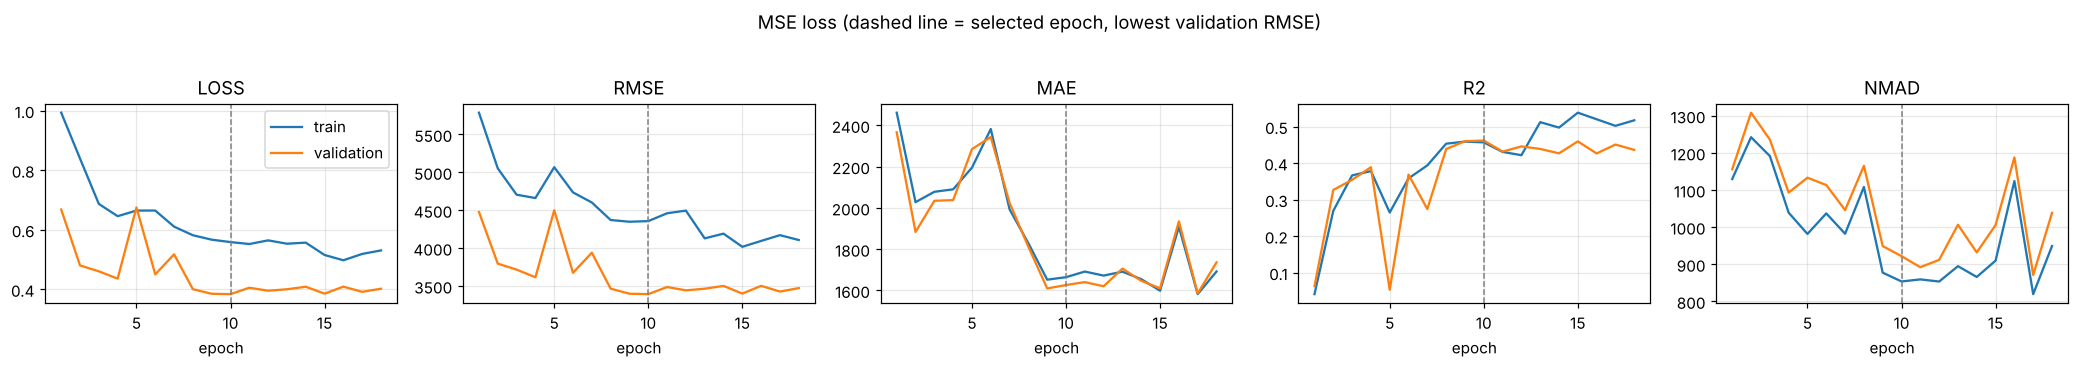

In [15]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 5, figsize=(19, 3.2))
    for ax, m in zip(axes, ["loss", "rmse", "mae", "r2", "nmad"]):
        tr = "train_loss" if m == "loss" else f"train_{m}"
        ax.plot(hist.epoch, hist[tr], label="train"); ax.plot(hist.epoch, hist[f"val_{m}"], label="validation")
        best = hist.loc[hist.val_rmse.idxmin()]
        ax.axvline(best.epoch, color="grey", ls="--", lw=1)
        ax.set_title(m.upper()); ax.set_xlabel("epoch")
    axes[0].legend(); fig.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

plot_history(hist_mse, "MSE loss (dashed line = selected epoch, lowest validation RMSE)")

The training RMSE is *higher* than the validation RMSE because, in this sample, the most extreme targets fell in the training split. With heavy tails, RMSE is driven by a handful of records (see the concerns at the end). Everything for the run is on disk:

In [16]:
print(sorted(os.listdir(train_cfg.output_dir))[:6], "...", f"({len(os.listdir(train_cfg.output_dir))} files)")
print(open(Path(train_cfg.output_dir) / "train.log").read().splitlines()[0])

['best_model.pt', 'config.json', 'epoch_001.pt', 'epoch_002.pt', 'epoch_003.pt', 'epoch_004.pt'] ... (22 files)
03:53:14 | device=cpu amp=off params=64,913 train=4,800 val=1,200 loss=mse fusion=late


## 7. Tweedie loss and tuning the power `p`

With a log link (`f = log μ`), the network minimises the negative Tweedie log-likelihood:

$$\ell(y, f) = -\frac{y\,e^{(1-p) f}}{1-p} + \frac{e^{(2-p) f}}{2-p}\qquad(p=1:\ e^f - y f,\quad p=2:\ y e^{-f} + f)$$

* For **every** `p` the optimum is `μ = E[y | x]`. The power only sets how residuals are weighted (variance ∝ μ^p), so a larger `p` down-weights errors on large targets.
* `p` **cannot be learned through this loss**, because the dropped normalising constant depends on `p`. Tune it on the validation set instead.
* `1 < p < 2` (compound Poisson–Gamma) puts probability mass at y = 0. Your target is strictly positive, so `p ≈ 2` (Gamma) to 3 (inverse Gaussian) is the natural family, but values in 1.5–2 often work well too. The grid below covers both.
* The target is divided by its training mean, so the initial output `f = 0` means "predict the mean".

Each `p` is selected on validation RMSE (the agreed criterion). The table also shows the validation Tweedie deviance at `p = 2` (Gamma deviance), which is closer to what these losses optimise.

In [17]:
prep_tw = Preprocessor(N_SPECIAL, group_sizes, target_mode=default_target_mode("tweedie")).fit(train_raw)
train_tw, val_tw = prep_tw.transform(train_raw), prep_tw.transform(val_raw)

P_GRID = [1.2, 1.5, 1.8, 2.0, 2.5]
tweedie_runs = {}
for p in P_GRID:
    cfg_p = TrainConfig(**{**train_cfg.to_dict(), "loss": "tweedie", "tweedie_power": p,
                           "output_dir": str(RUNS / f"tweedie_p{p}"), "verbose": False})
    t = Trainer(model_cfg, cfg_p, prep_tw)
    h = t.fit(train_tw, val_tw)
    best = h.loc[h.val_rmse.idxmin()]
    pred = t.predict(val_tw)
    tweedie_runs[p] = {"best_epoch": int(best.epoch), "epochs_run": len(h), "val_rmse": best.val_rmse,
                       "val_mae": best.val_mae, "val_r2": best.val_r2, "val_nmad": best.val_nmad,
                       "val_gamma_dev": tweedie_deviance(val_raw.y, pred, 2.0), "hist": h}
    print(f"p={p}: best epoch {int(best.epoch):2d}/{len(h)}  val RMSE {best.val_rmse:9.2f}  R2 {best.val_r2:.3f}")

mse_pred = trainer.predict(val_mse)
best_mse = hist_mse.loc[hist_mse.val_rmse.idxmin()]
summary = pd.DataFrame({**{f"tweedie p={p}": {k: v for k, v in r.items() if k != "hist"} for p, r in tweedie_runs.items()},
                        "mse": {"best_epoch": int(best_mse.epoch), "epochs_run": len(hist_mse), "val_rmse": best_mse.val_rmse,
                                "val_mae": best_mse.val_mae, "val_r2": best_mse.val_r2, "val_nmad": best_mse.val_nmad,
                                "val_gamma_dev": tweedie_deviance(val_raw.y, mse_pred, 2.0)}}).T
summary.astype(float).round(4)

p=1.2: best epoch 26/34  val RMSE   3276.17  R2 0.498


p=1.5: best epoch 30/38  val RMSE   3200.70  R2 0.521


p=1.8: best epoch 21/29  val RMSE   3331.65  R2 0.481


p=2.0: best epoch 24/32  val RMSE   3275.13  R2 0.498


p=2.5: best epoch 27/35  val RMSE   3298.91  R2 0.491


,best_epoch,epochs_run,val_rmse,val_mae,val_r2,val_nmad,val_gamma_dev
tweedie p=1.2,26.0,34.0,3276.1732,1569.1357,0.4980,950.4531,0.6602
tweedie p=1.5,30.0,38.0,3200.7004,1551.4263,0.5209,970.7975,0.6243
tweedie p=1.8,21.0,29.0,3331.6524,1560.4671,0.4808,911.9925,0.6523
tweedie p=2.0,24.0,32.0,3275.1273,1580.6393,0.4983,942.8834,0.6322
tweedie p=2.5,27.0,35.0,3298.9120,1567.7700,0.4910,971.2534,0.6358
mse,10.0,18.0,3392.9880,1626.2122,0.4616,921.7574,1.2534


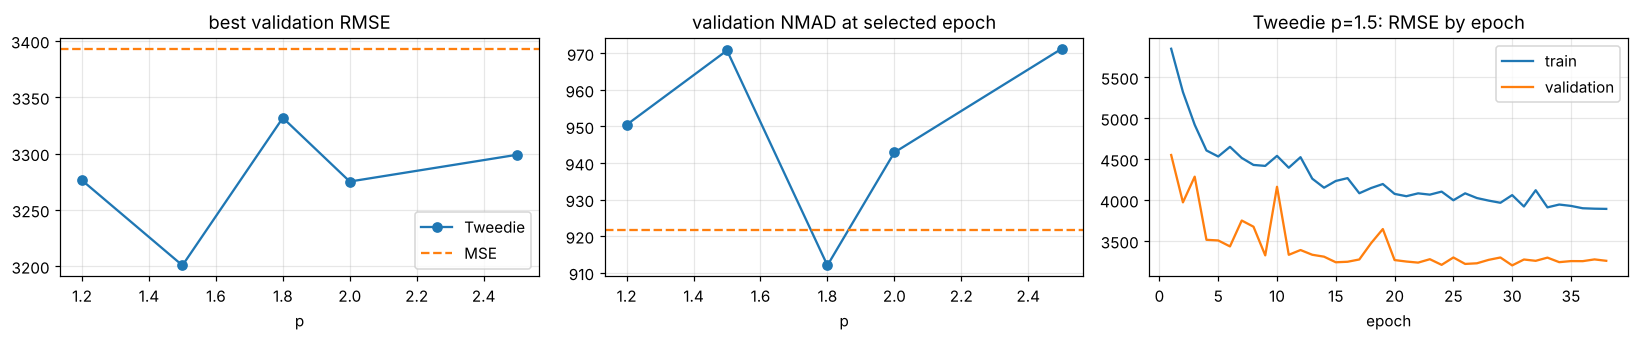

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].plot(P_GRID, summary.loc[[f"tweedie p={p}" for p in P_GRID], "val_rmse"], "o-", label="Tweedie")
ax[0].axhline(best_mse.val_rmse, color="C1", ls="--", label="MSE"); ax[0].set_xlabel("p"); ax[0].set_title("best validation RMSE"); ax[0].legend()
ax[1].plot(P_GRID, summary.loc[[f"tweedie p={p}" for p in P_GRID], "val_nmad"], "o-")
ax[1].axhline(best_mse.val_nmad, color="C1", ls="--"); ax[1].set_xlabel("p"); ax[1].set_title("validation NMAD at selected epoch")
best_p = min(tweedie_runs, key=lambda p: tweedie_runs[p]["val_rmse"])
h = tweedie_runs[best_p]["hist"]
ax[2].plot(h.epoch, h.train_rmse, label="train"); ax[2].plot(h.epoch, h.val_rmse, label="validation")
ax[2].set_title(f"Tweedie p={best_p}: RMSE by epoch"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

**What this run shows.** This is synthetic data and one seed per setting, so read it as an illustration, not a result:

* Every Tweedie power beat MSE on validation RMSE. The best was p = 1.5, with RMSE ≈ 3,201 against 3,393 and R² 0.52 against 0.46. That happened even though RMSE is exactly what MSE optimises; the log link suits a multiplicative, right-skewed target.
* The MSE model's Gamma deviance (a relative-error measure) is about **twice** that of every Tweedie model. It is much less accurate *relative to the size* of small and medium targets, and RMSE does not reveal that.
* The metrics disagree on ranking: MSE has one of the lowest NMADs, and p = 1.8 is the worst on RMSE but the best on NMAD. Differences between powers (about ±100 RMSE) are of the same order as seed-to-seed noise (notebook 02). On your data, tune `p` over several seeds, and decide which metric reflects the business objective before you select.

## 8. Reload the selected model and evaluate

`load_checkpoint` rebuilds the model **and** the fitted preprocessor from a checkpoint, so new data only needs to arrive in the `RawData` format. Checkpoints contain only tensors and Python primitives, so they load with `torch.load(weights_only=True)`. The overall winner is picked by validation RMSE.

In [19]:
candidates = {"mse": (best_mse.val_rmse, RUNS / "mse")}
candidates.update({f"tweedie p={p}": (r["val_rmse"], RUNS / f"tweedie_p{p}") for p, r in tweedie_runs.items()})
winner = min(candidates, key=lambda k: candidates[k][0])
print("selected:", winner, "| validation RMSE", round(candidates[winner][0], 3))

model_best, prep_best, cfg_best, ckpt = load_checkpoint(str(candidates[winner][1] / "best_model.pt"), device="cpu")
val_pred = predict_with(model_best, prep_best, cfg_best, prep_best.transform(val_raw))
print("epoch", ckpt["epoch"], "| recomputed:", {k: round(v, 4) for k, v in regression_metrics(val_raw.y, val_pred).items()})

selected: tweedie p=1.5 | validation RMSE 3200.7


epoch 30 | recomputed: {'rmse': 3200.7004, 'mae': 1551.4263, 'r2': 0.5209, 'nmad': 970.7975}


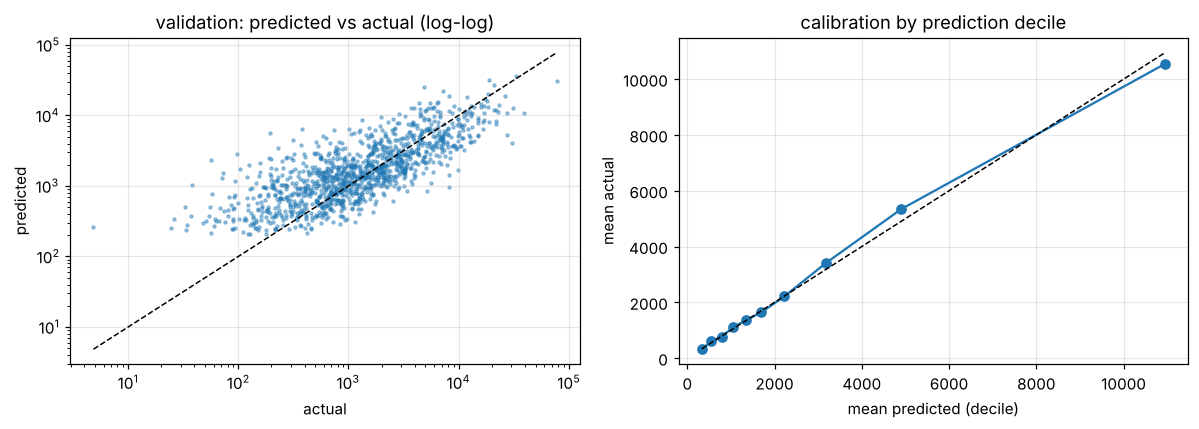

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(val_raw.y, val_pred, s=4, alpha=0.4)
lim = [min(val_raw.y.min(), val_pred.min()), max(val_raw.y.max(), val_pred.max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("actual"); ax[0].set_ylabel("predicted"); ax[0].set_title("validation: predicted vs actual (log-log)")
dec = pd.qcut(val_pred, 10, labels=False)
cal = pd.DataFrame({"pred": val_pred, "y": val_raw.y, "dec": dec}).groupby("dec").mean()
ax[1].plot(cal.pred, cal.y, "o-"); ax[1].plot(cal.pred, cal.pred, "k--", lw=1)
ax[1].set_xlabel("mean predicted (decile)"); ax[1].set_ylabel("mean actual"); ax[1].set_title("calibration by prediction decile")
plt.tight_layout(); plt.show()

**Resuming** an interrupted run: `t = Trainer(model_cfg, train_cfg, prep); start = t.resume(".../epoch_012.pt"); t.fit(train, val, start_epoch=start)`.

## 9. Checklist for your data

1. **Alignment.** Build `x`, `missing`, `special`, `snapshot` and `y` with the *same* `record_ids` order, as `to_raw` does above.
2. **Codes.** Set `n_special_codes = K`. Special codes must be 1..K, with 0 meaning "not special".
3. **PLE groups.** `snapshot_group_sizes` lists the number of PLE columns for each variable, in column order. PLE must be fitted on train only, and missing snapshot values need an explicit encoding (NaN raises an error).
4. **Size.** Each grid branch has `(V+1)·(Np+1)` tokens per record. With many variables (say V > 200), lower `batch_size` or `d_model`, use a larger `patch_stride`, or keep `use_amp=True`. Peak GPU memory per epoch is logged as `gpu_peak_mem_mb`.
5. **Warm-up.** `warmup_steps` is counted in optimizer steps. Use about 1–3 epochs' worth.
6. **Tuning.** `d_model`, `n_ts_layers`, `patch_len`/`patch_stride`, `dropout`, `lr`, `batch_size` and the Tweedie `p` are the main knobs. Compare runs on validation, and keep a separate test set for the final number, because choosing among many runs on validation RMSE overfits the validation set.

`02_alternative_value_aware_tokens.ipynb` compares this late-fusion design with a value-aware-token alternative.